# Did Delhi's Odd–Even rule reduce air pollution? Difference-in-differences analysis

This notebook reproduces every number, table and figure in the term paper.
Run it top to bottom (Runtime → Run all).

**Data:** *Air Quality Data in India (2015–2020)*, Kaggle (Vopani / Rohan Rao), compiled from CPCB monitoring stations.
Put `stations.csv` and `station_hour.csv` in a Google Drive folder called `odd_even_data`.

**Design in one line:** compare the change in Delhi's 8am–8pm pollution (rule days vs the 14 days before)
with the same change in Gurugram, which had no rule.

## 0. Setup

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:                                   # Google Colab: read data from Drive
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/odd_even_data'
except ImportError:                    # running elsewhere
    DATA_DIR = os.environ.get('DATA_DIR', 'data')
OUT_DIR = os.path.join(DATA_DIR, 'outputs')
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.precision', 3)
print('Data folder:', DATA_DIR, '| outputs go to:', OUT_DIR)

Data folder: data | outputs go to: data/outputs


### Choices made before looking at any results

| Choice | Value | Why |
|---|---|---|
| Treated stations | 10 Delhi monitors running since 2015 ("legacy 10") | Same fixed set in every round; closer in size to Gurugram's 2 |
| Control stations | Gurugram: Vikas Sadan (HR014), Gwal Pahari (HR011, from Dec 2017) | Next to Delhi, same weather and smog, no Odd–Even |
| Outcome | log of the 08:00–19:59 mean (the hours the rule applied) | Logs → effects read as % changes |
| Valid day | at least 6 of the 12 hours present | Avoids days built from 1–2 readings |
| Before window | 14 days before each round | Same season and weather |
| Dropped days | Diwali ±1 day in every window; Sundays in every window (before, rule and fake windows); 11–12 Nov 2019 | Festival smoke; rule never applied on Sundays |
| Weekday balance | Before-days reweighted to the rule days' Monday–Saturday mix, in every estimate and placebo | Delhi and Gurugram may have different weekday patterns |
| Main round | Nov 2019 | Complete data for both cities |

In [2]:
LEGACY10 = ['DL002','DL007','DL008','DL013','DL014','DL019','DL021','DL028','DL031','DL033']
SW5      = ['DL021','DL010','DL012','DL004','DL022']     # Delhi monitors nearest Gurugram
GGN      = ['HR014','HR011']
OTHER_NORTH = ['Chandigarh','Amritsar','Jaipur','Lucknow','Patna']
POLL     = ['PM2.5','NO2','SO2']
MIN_HOURS, PRE_DAYS = 6, 14

def days(a, b): return pd.date_range(a, b)
DIWALI = pd.to_datetime(['2015-11-11','2016-10-30','2017-10-19','2018-11-07','2019-10-27'])
DIWALI_DROP = pd.DatetimeIndex(sorted({d + pd.Timedelta(days=k) for d in DIWALI for k in (-1, 0, 1)}))

ROUNDS = {
    'Jan 2016': [d for d in days('2016-01-01','2016-01-15') if d.dayofweek != 6],
    'Apr 2016': [d for d in days('2016-04-15','2016-04-30') if d.dayofweek != 6],
    'Nov 2019': [d for d in days('2019-11-04','2019-11-15') if d.dayofweek != 6 and d.day not in (11, 12)],
}
ROUNDS = {k: pd.DatetimeIndex(v) for k, v in ROUNDS.items()}
# periods that must never be used as 'fake' policy windows
BLOCKED = [(v.min() - pd.Timedelta(days=21), v.max() + pd.Timedelta(days=7)) for v in ROUNDS.values()]
BLOCKED.append((pd.Timestamp('2017-11-06'), pd.Timestamp('2017-11-24')))   # announced (then cancelled) Nov 2017 round
BLOCKED.append((pd.Timestamp('2020-03-15'), pd.Timestamp('2020-12-31')))   # COVID-19 lockdown: traffic collapsed
BLOCKED.append((pd.Timestamp('2019-09-13'), pd.Timestamp('2019-11-03')))   # Nov 2019 round announced: possible anticipation, not a clean fake period

def clean(idx):
    """Drop Diwali ±1 day and Sundays (the rule never applied on Sundays), so every window has the same weekday mix."""
    idx = pd.DatetimeIndex(idx).difference(DIWALI_DROP)
    return idx[idx.dayofweek != 6]

def pre_window(rule, n=PRE_DAYS):
    s = rule.min()
    return clean(days(s - pd.Timedelta(days=n), s - pd.Timedelta(days=1)))

for r, v in ROUNDS.items():
    print(f'{r}: {len(v)} rule days {v.min():%d %b}–{v.max():%d %b %Y}; before window {len(pre_window(v))} days')

Jan 2016: 13 rule days 01 Jan–15 Jan 2016; before window 12 days
Apr 2016: 14 rule days 15 Apr–30 Apr 2016; before window 12 days
Nov 2019: 9 rule days 04 Nov–15 Nov 2019; before window 10 days


## 1. Load data and build the station-day panel

In [3]:
t0 = time.time()
stations = pd.read_csv(os.path.join(DATA_DIR, 'stations.csv'))
city_of = stations.set_index('StationId').City
keep = stations.loc[stations.City.isin(['Delhi','Gurugram'] + OTHER_NORTH), 'StationId']
sh = pd.read_csv(os.path.join(DATA_DIR, 'station_hour.csv'), usecols=['StationId','Datetime'] + POLL)
sh = sh[sh.StationId.isin(keep)].copy()
sh['Datetime'] = pd.to_datetime(sh.Datetime)
sh['date'] = sh.Datetime.dt.normalize()
sh['period'] = np.where(sh.Datetime.dt.hour.between(8, 19), 'day', 'night')   # day = 08:00–19:59
g = sh.groupby(['StationId','date','period'])
daily = g[POLL].mean().where(g[POLL].count() >= MIN_HOURS).reset_index()
daily['City'] = daily.StationId.map(city_of)
print(f'{len(sh):,} hourly rows → {len(daily):,} station-day-period rows in {time.time()-t0:.0f}s')
ALL_DL = sorted(daily.loc[daily.City == 'Delhi', 'StationId'].unique())
CITY_IDS = {c: sorted(daily.loc[daily.City == c, 'StationId'].unique()) for c in ['Gurugram'] + OTHER_NORTH}
print('Delhi stations with data:', len(ALL_DL), '| Gurugram:', CITY_IDS['Gurugram'])

1,475,997 hourly rows → 123,106 station-day-period rows in 4s
Delhi stations with data: 38 | Gurugram: ['HR011', 'HR012', 'HR013', 'HR014']


In [4]:
def station_panel(ids, pol, period='day'):
    """log outcome per station-day; period = 'day', 'night' or 'gap' (log day − log night)."""
    if period == 'gap':
        d = station_panel(ids, pol, 'day').set_index(['StationId','date']).y
        n = station_panel(ids, pol, 'night').set_index(['StationId','date']).y
        return (d - n).dropna().rename('y').reset_index()
    x = daily[(daily.StationId.isin(ids)) & (daily.period == period)][['StationId','date',pol]].dropna()
    x = x[x[pol] > 0]
    return x.assign(y=np.log(x[pol]))[['StationId','date','y']]

def city_series(ids, pol, period='day'):
    """log of the mean across the given stations, per day."""
    if period == 'gap':
        return (city_series(ids, pol, 'day') - city_series(ids, pol, 'night')).dropna()
    x = daily[(daily.StationId.isin(ids)) & (daily.period == period)].groupby('date')[pol].mean()
    return np.log(x[x > 0])

pct = lambda b: 100 * (np.exp(b) - 1)

## 2. Estimators

**Weekday balance.** Dropping Sundays does not make the before-window and the rule days have the same mix of
Monday–Saturday (e.g. Nov 2019: the before-window has two Tuesdays, the rule days one). Every estimator below therefore
**reweights before-days so that their weekday shares match the rule days'** (`weekday_weights`). The same reweighting is
applied inside every placebo window, because the placebo estimates call the same functions.

* `did_city` – the simple 2×2: (Delhi after − before) − (Gurugram after − before), on city averages.
* `twfe` – the main regression on station-days: log Y = station FE + date FE + δ·D. δ is the DiD.
  The same function gives the **triple difference** when the outcome is (log day − log night),
  and the **within-Delhi day–night DiD** when the units are Delhi station×period.

In [5]:
def weekday_weights(dates, pre, post):
    """Weight 1 for post (rule) days; for pre days, share of that weekday among post days divided by its share among
    pre days, so the reweighted before-window has the rule days' weekday mix. Weekdays absent from post get weight 0."""
    dates = pd.DatetimeIndex(dates)
    sp = pd.Series(pd.DatetimeIndex(post).dayofweek).value_counts(normalize=True)
    sq = pd.Series(pd.DatetimeIndex(pre).dayofweek).value_counts(normalize=True)
    w = np.ones(len(dates))
    ispre = dates.isin(pre)
    w[ispre] = [sp.get(d, 0.0) / sq[d] for d in dates[ispre].dayofweek]
    return w

def did_city(tr, ct, pre, post, min_share=0.5):
    s = pd.concat({'t': tr, 'c': ct}, axis=1)
    a, b = s.reindex(pre).dropna(), s.reindex(post).dropna()
    if len(a) < min_share * len(pre) or len(b) < min_share * len(post):
        return np.nan
    wa = weekday_weights(a.index, pre, post)
    if wa.sum() == 0: return np.nan
    ga = np.average(a.t - a.c, weights=wa)
    return (b.t - b.c).mean() - ga

def twfe_df(df, pre, post, min_share=0.5):
    """df: columns unit, date, y, tr (bool). Returns (delta, n_obs)."""
    df = df[df.date.isin(pre.union(post))]
    for grp in (True, False):                       # both groups must be seen before and after
        dd = df[df.tr == grp].date
        if dd.isin(pre).groupby(dd).any().sum() < min_share * len(pre) or \
           dd.isin(post).groupby(dd).any().sum() < min_share * len(post):
            return np.nan, 0
    w = weekday_weights(df.date, pre, post)          # weighted least squares: before-days match the rule-day weekday mix
    keep = w > 0; df = df[keep]; w = w[keep]
    D = (df.tr & df.date.isin(post)).astype(float).values
    U = pd.get_dummies(df.unit, drop_first=True, dtype=float).values
    T = pd.get_dummies(df.date, drop_first=True, dtype=float).values
    X = np.column_stack([np.ones(len(df)), D, U, T])
    sw = np.sqrt(w)
    beta = np.linalg.lstsq(X * sw[:, None], df.y.values * sw, rcond=None)[0]
    return beta[1], len(df)

def twfe(tr_ids, ct_ids, pol, pre, post, period='day'):
    a = station_panel(tr_ids, pol, period).assign(tr=True)
    b = station_panel(ct_ids, pol, period).assign(tr=False)
    return twfe_df(pd.concat([a, b]).rename(columns={'StationId': 'unit'}), pre, post)

def within_delhi(ids, pol, pre, post):
    """Delhi only: day hours (treated) vs night hours (control) of the same stations."""
    d = station_panel(ids, pol, 'day').assign(tr=True)
    n = station_panel(ids, pol, 'night').assign(tr=False)
    df = pd.concat([d, n]); df['unit'] = df.StationId + '_' + df.tr.map({True: 'day', False: 'night'})
    return twfe_df(df, pre, post)

## 3. Placebo-date (permutation) inference

Treatment is assigned to one city (Delhi) on a set of dates. Delhi's 10 stations all receive the same city-level
treatment, so they are not 10 independent treated units, and clustered standard errors with one treated cluster are not reliable.
Instead we ask: *if we pretend the rule started on a date when nothing happened, how often is the estimate as large as the real one?*

Fake start dates: every date within ±75 days of the real start's calendar day, in other years with data, that falls on the
**same weekday** as the real start (e.g. a Monday for 4 Nov 2019). Fake rule days copy the real pattern of rule days,
so every fake window has the **same number and weekday mix of rule days** as the real one. Windows that touch Diwali, any real
or announced Odd–Even round, or the 2020 COVID lockdown are skipped. Sundays are dropped from before-windows as in the real data.
(The earlier, looser version — any weekday, ±45 days — is kept as a sensitivity check.)

**Placebo p-value = share of fake-date estimates whose absolute size is at least as large as the real estimate's** (two-sided).
This is a formal randomisation-inference p-value only if the real start date is exchangeable with the fake ones.
The real date was chosen for a smoggy season, which is why fakes come from the same season; but the date was not random,
so we read the p-value as *how unusual the real estimate is compared with ordinary periods*, and we do not invert it into confidence intervals.

In [6]:
AFTER_DAYS = 15
def fake_windows(rule, matched=True, span=75):
    """Returns (fake start, before-window, fake rule days, after-window) tuples.
    matched=True: same weekday as the real start, so fake rule days have the same count and weekday mix;
    windows touching Diwali are skipped. matched=False: the looser earlier version (any weekday, ±45 days)."""
    s = rule.min(); offs = [(d - s).days for d in rule]; L = max(offs)
    span = span if matched else 45
    out = []
    for yr in range(2015, 2021):
        try: centre = s.replace(year=yr)
        except ValueError: continue
        for k in range(-span, span + 1):
            F = centre + pd.Timedelta(days=k)
            if matched and F.dayofweek != s.dayofweek: continue
            lo, hi = F - pd.Timedelta(days=PRE_DAYS), F + pd.Timedelta(days=L + AFTER_DAYS)
            if any(lo <= b and hi >= a for a, b in BLOCKED): continue
            if matched and days(lo, F + pd.Timedelta(days=L)).isin(DIWALI_DROP).any(): continue
            pre = clean(days(lo, F - pd.Timedelta(days=1)))
            post = clean([F + pd.Timedelta(days=o) for o in offs]) if not matched else pd.DatetimeIndex([F + pd.Timedelta(days=o) for o in offs])
            E = F + pd.Timedelta(days=L)
            aft = clean(days(E + pd.Timedelta(days=1), E + pd.Timedelta(days=AFTER_DAYS)))
            out.append((F, pre, post, aft))
    return out

def after_window(rule, n=AFTER_DAYS):
    e = rule.max(); return clean(days(e + pd.Timedelta(days=1), e + pd.Timedelta(days=n)))

def ri(estimator, actual, rule, years=None, matched=True, months=None):
    W = [w for w in fake_windows(rule, matched) if (years is None or w[0].year in years) and (months is None or w[0].month in months)]
    fakes = np.array([estimator(pre, post) for F, pre, post, aft in W], dtype=float)
    fakes = fakes[~np.isnan(fakes)]
    if np.isnan(actual) or len(fakes) == 0: return np.nan, len(fakes), fakes
    return np.mean(np.abs(fakes) >= abs(actual)), len(fakes), fakes

def placebo_range(fakes):
    """5th and 95th percentile of the fake (placebo) estimates, in %. Describes ordinary variation; NOT a confidence interval."""
    if len(fakes) < 15: return np.nan, np.nan
    return pct(np.percentile(fakes, 5)), pct(np.percentile(fakes, 95))

## 4. Table 1 – summary statistics (8am–8pm daily means, µg/m³)

In [7]:
rows = []
for r, rule in ROUNDS.items():
    pre = pre_window(rule)
    for pol in ['PM2.5','NO2']:
        for city, ids in [('Delhi (10 monitors)', LEGACY10), ('Gurugram', GGN)]:
            lvl = np.exp(city_series(ids, pol))
            for per, dts in [('Before', pre), ('During', rule)]:
                v = lvl.reindex(dts).dropna()
                rows.append(dict(Round=r, Pollutant=pol, City=city, Period=per, Days=len(v),
                                 Mean=v.mean(), SD=v.std(), Median=v.median()))
table1 = pd.DataFrame(rows)
table1.to_csv(os.path.join(OUT_DIR, 'table1_summary_stats.csv'), index=False)
print(table1.round(1).to_string(index=False))

   Round Pollutant                City Period  Days  Mean    SD  Median
Jan 2016     PM2.5 Delhi (10 monitors) Before    12 155.9  59.6   129.9
Jan 2016     PM2.5 Delhi (10 monitors) During    13 233.6  77.3   229.0
Jan 2016     PM2.5            Gurugram Before     0   NaN   NaN     NaN
Jan 2016     PM2.5            Gurugram During     0   NaN   NaN     NaN
Jan 2016       NO2 Delhi (10 monitors) Before    12  67.4  28.2    68.9
Jan 2016       NO2 Delhi (10 monitors) During    13  83.5  24.2    76.9
Jan 2016       NO2            Gurugram Before     8  14.8   2.0    14.2
Jan 2016       NO2            Gurugram During     6  12.2   3.5    11.1
Apr 2016     PM2.5 Delhi (10 monitors) Before    12  90.5  20.6    79.8
Apr 2016     PM2.5 Delhi (10 monitors) During    14 116.0  27.7   114.6
Apr 2016     PM2.5            Gurugram Before     6  76.6  13.5    78.0
Apr 2016     PM2.5            Gurugram During    11 126.7  41.2   118.9
Apr 2016       NO2 Delhi (10 monitors) Before    12  36.7  19.9 

In [8]:
# monitors reporting per day (at least 6 daytime hours) in each window
# Delhi's daily value is the equal-weight mean of the stations that report that day, so we check how many contribute.
cov = []
for r, rule in ROUNDS.items():
    for per, dts in [('Before', pre_window(rule)), ('During', rule)]:
        for name, ids in [('Delhi legacy 10', LEGACY10), ('Delhi all', ALL_DL), ('Gurugram', GGN)]:
            for pol in ['PM2.5','NO2']:
                x = daily[(daily.StationId.isin(ids)) & (daily.period == 'day') & daily.date.isin(dts)]
                n = x.dropna(subset=[pol]).groupby('date').StationId.nunique().reindex(dts, fill_value=0)
                cov.append(dict(Round=r, Period=per, Group=name, Pollutant=pol,
                                mean_stations=round(n.mean(), 1), min_stations=int(n.min())))
coverage = pd.DataFrame(cov); coverage.to_csv(os.path.join(OUT_DIR, 'station_coverage.csv'), index=False)
# weekday composition of each window (before reweighting)
wk = []
for r, rule in ROUNDS.items():
    for per, dts in [('Before', pre_window(rule)), ('Rule days', rule)]:
        c = pd.Series(pd.DatetimeIndex(dts).dayofweek).value_counts().reindex(range(6), fill_value=0)
        wk.append(dict(Round=r, Window=per, **dict(zip(['Mon','Tue','Wed','Thu','Fri','Sat'], c.values))))
weekday_mix = pd.DataFrame(wk); weekday_mix.to_csv(os.path.join(OUT_DIR, 'weekday_mix.csv'), index=False)
print(weekday_mix.to_string(index=False))
coverage.pivot_table(index=['Group','Pollutant'], columns=['Round','Period'], values='mean_stations', sort=False)

   Round    Window  Mon  Tue  Wed  Thu  Fri  Sat
Jan 2016    Before    2    2    2    2    2    2
Jan 2016 Rule days    2    2    2    2    3    2
Apr 2016    Before    2    2    2    2    2    2
Apr 2016 Rule days    2    2    2    2    3    3
Nov 2019    Before    1    2    2    2    2    1
Nov 2019 Rule days    1    1    2    2    2    1


Round                     Jan 2016        Apr 2016        Nov 2019       
Period                      Before During   Before During   Before During
Group           Pollutant                                                
Delhi legacy 10 PM2.5          4.5    5.3      3.4    5.1      9.5   10.0
                NO2            5.5    5.7      3.3    5.1      9.5    9.4
Delhi all       PM2.5          4.5    5.3      3.4    5.1     36.3   36.9
                NO2            5.5    5.7      3.9    5.3     36.6   37.2
Gurugram        PM2.5          0.0    0.0      0.5    0.8      2.0    2.0
                NO2            0.7    0.5      0.8    0.6      2.0    2.0

## 5. Main results (Table 2)

Columns: (1) simple 2×2 on city averages, (2) **main: station-level DiD with station and date fixed effects**,
(3) triple difference (day vs night), (4) within-Delhi day–night DiD (needs no control city; the only option for Jan 2016).

In [9]:
t0 = time.time()
main_rows, RI_DRAWS = [], {}
for r, rule in ROUNDS.items():
    pre = pre_window(rule)
    for pol in ['PM2.5','NO2']:
        est = {
         '(1) 2x2 city':     lambda p, q: did_city(city_series(LEGACY10, pol), city_series(GGN, pol), p, q),
         '(2) DiD station FE (main)': lambda p, q: twfe(LEGACY10, GGN, pol, p, q)[0],
         '(3) Triple diff':  lambda p, q: twfe(LEGACY10, GGN, pol, p, q, 'gap')[0],
         '(4) Delhi day vs night': lambda p, q: within_delhi(LEGACY10, pol, p, q)[0],
        }
        nobs = {'(2) DiD station FE (main)': twfe(LEGACY10, GGN, pol, pre, rule)[1],
                '(3) Triple diff': twfe(LEGACY10, GGN, pol, pre, rule, 'gap')[1],
                '(4) Delhi day vs night': within_delhi(LEGACY10, pol, pre, rule)[1]}
        for name, f in est.items():
            b = f(pre, rule)
            p, n, draws = ri(f, b, rule)
            RI_DRAWS[(r, pol, name)] = (b, draws)
            lo, hi = placebo_range(draws)
            main_rows.append(dict(Round=r, Pollutant=pol, Model=name, log_coef=b, effect_pct=pct(b),
                                  placebo_p=p, placebo_draws=n, placebo_p5_pct=lo, placebo_p95_pct=hi,
                                  N=nobs.get(name, len(pre) + len(rule))))
table2 = pd.DataFrame(main_rows)
table2.to_csv(os.path.join(OUT_DIR, 'table2_main_results.csv'), index=False)
print(f'done in {time.time()-t0:.0f}s')
table2.pivot_table(index=['Round','Pollutant'], columns='Model', values=['effect_pct','placebo_p'], sort=False).round(3)

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

... (48 outputs left out)

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

done in 81s


effect_pct                                                                     placebo_p                                                                 
Model              (1) 2x2 city (2) DiD station FE (main) (3) Triple diff (4) Delhi day vs night (1) 2x2 city (2) DiD station FE (main) (3) Triple diff (4) Delhi day vs night
Round    Pollutant                                                                                                                                                            
Jan 2016 PM2.5              NaN                       NaN             NaN                 -3.898          NaN                       NaN             NaN                  0.699
         NO2                NaN                       NaN             NaN                  6.303          NaN                       NaN             NaN                  0.589
Apr 2016 PM2.5          -17.606                    -4.819             NaN                  5.952        0.333                     0.778             NaN                  0.620
         NO2             98.379                    25.971           4.388                -12.512        0.242                     0.629           0.810                  0.141
Nov 2019 PM2.5          -10.011                    -9.297         -10.874                 -3.775        0.571                     0.643           0.381                  0.789
         NO2            -16.708                   -13.540           2.644                 10.606        0.514                     0.459           0.973                  0.368

## 6. Figure 1 – event study, Nov 2019

Each point is the Delhi–Gurugram gap in log points (×100, roughly %) on that day minus the average gap over the before window
(this normalises the pre-period average to zero, as in Miller 2023; the before-window average is weekday-reweighted). Before the rule the points should sit near zero.
The grey band is the 5th–95th percentile of the same number across all fake start dates (placebo band).
Sundays are plotted (open points) but are not in the before-window average.

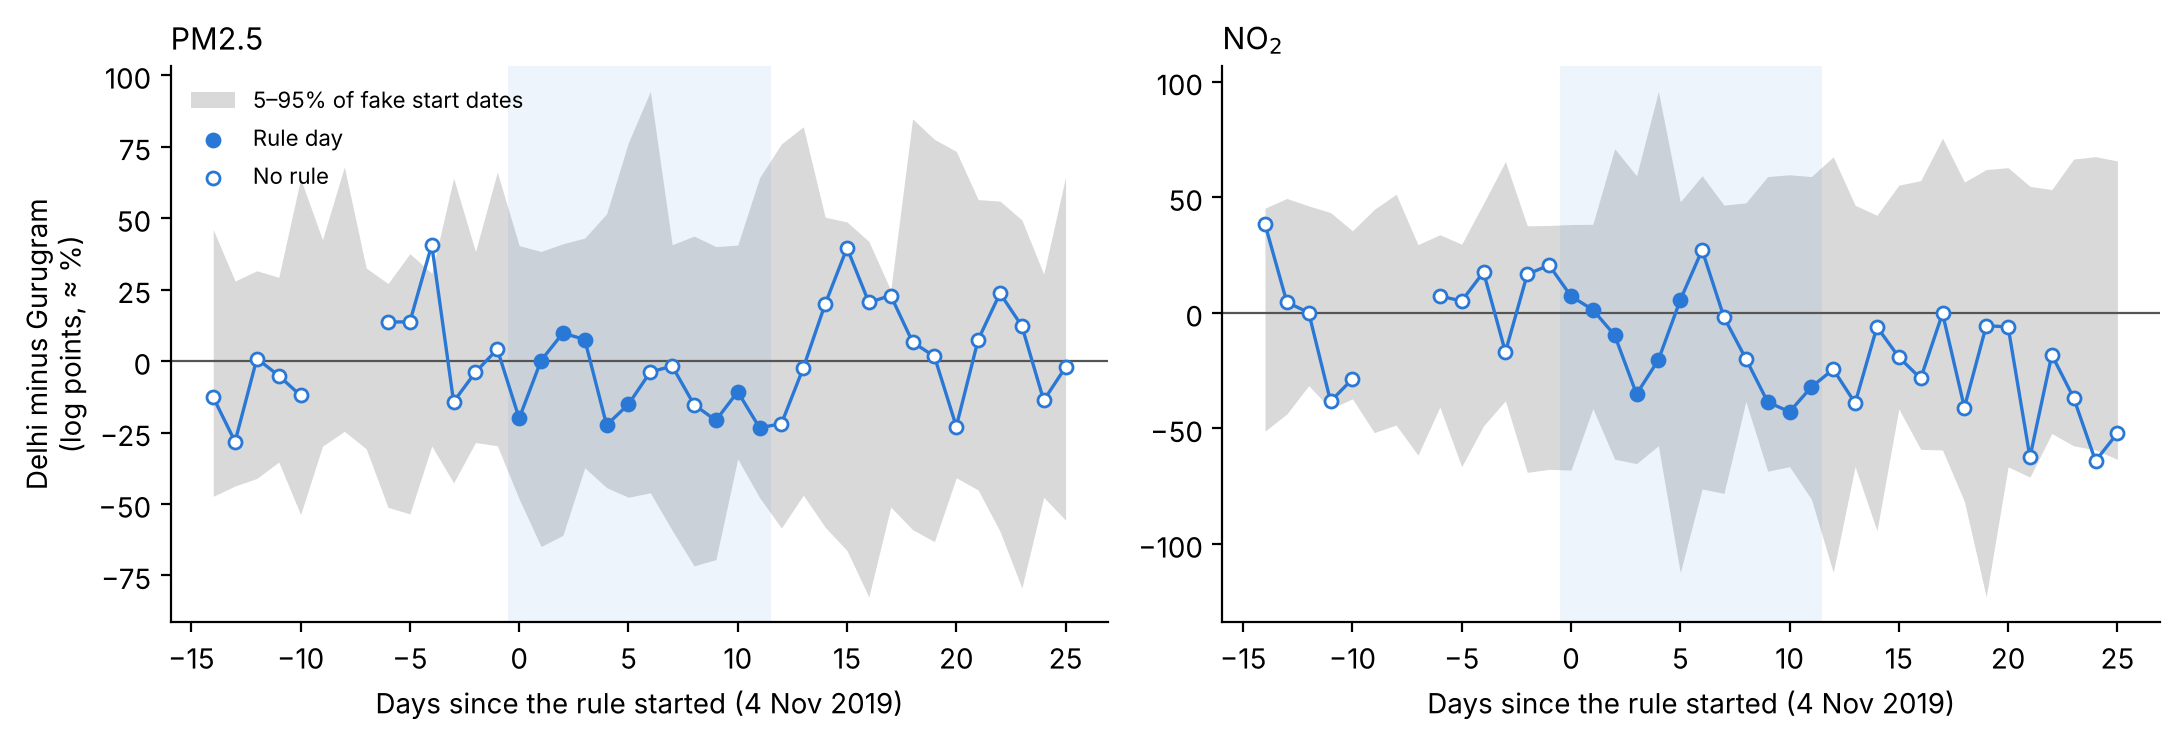

In [10]:
def event_path(tr, ct, start, pre, ks, post=None):
    gap = tr - ct
    g = gap.reindex(pre).dropna()
    base = np.average(g, weights=weekday_weights(g.index, pre, post)) if post is not None and len(g) else g.mean()
    dts = [start + pd.Timedelta(days=k) for k in ks]
    e = gap.reindex(dts).values - base
    e[pd.DatetimeIndex(dts).isin(DIWALI_DROP)] = np.nan
    return e

rule = ROUNDS['Nov 2019']; ks = np.arange(-14, 26); S = rule.min()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
EVENT = {}
for ax, pol in zip(axes, ['PM2.5','NO2']):
    tr, ct = city_series(LEGACY10, pol), city_series(GGN, pol)
    e = event_path(tr, ct, S, pre_window(rule), ks, rule)
    band = np.array([event_path(tr, ct, F, p, ks, q) for F, p, q, a in fake_windows(rule)])
    lo, hi = np.nanpercentile(band, 5, axis=0), np.nanpercentile(band, 95, axis=0)
    EVENT[pol] = pd.DataFrame({'k': ks, 'gap_logpts': 100*e, 'band_lo_logpts': 100*lo, 'band_hi_logpts': 100*hi})
    rule_k = [(d - S).days for d in rule]
    ax.fill_between(ks, 100*lo, 100*hi, color='#d9d9d9', lw=0, label='5–95% of fake start dates')
    ax.axvspan(-0.5, max(rule_k) + 0.5, color='#2a78d6', alpha=0.08, lw=0)
    ax.axhline(0, color='#555', lw=0.8)
    is_rule = np.isin(ks, rule_k)
    ax.plot(ks, 100*e, color='#2a78d6', lw=1.2)
    ax.scatter(ks[is_rule], (100*e)[is_rule], color='#2a78d6', s=22, zorder=3, label='Rule day')
    ax.scatter(ks[~is_rule], (100*e)[~is_rule], facecolor='white', edgecolor='#2a78d6', s=22, zorder=3, label='No rule')
    ax.set_title({'PM2.5': 'PM2.5', 'NO2': 'NO$_2$'}[pol], loc='left', fontsize=11)
    ax.set_xlabel('Days since the rule started (4 Nov 2019)')
    ax.spines[['top','right']].set_visible(False)
axes[0].set_ylabel('Delhi minus Gurugram\n(log points, ≈ %)')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'figure1_event_study.png'), dpi=200)
plt.show()
for pol in EVENT: EVENT[pol].to_csv(os.path.join(OUT_DIR, f'figure1_event_study_{pol}.csv'), index=False)

## 7. Pre-trends, placebos, robustness and after-rule analysis (Table 3)

Built by one function so the same checks run for Nov 2019 (in the paper) and Apr 2016 (notebook appendix).
Jan 2016 cannot be checked this way: Gurugram has no PM2.5 and almost no NO2 then.
Each check changes ONE choice. Rows marked with a placebo p use the same matched fake dates as Table 2.

In [11]:
import statsmodels.api as sm
def pretrend(pol, pre_dates):
    """Slope of the daily Delhi–Gurugram log gap over a before window; Newey–West (HAC, 2 lags) t-stat. Descriptive only."""
    gap = (city_series(LEGACY10, pol) - city_series(GGN, pol)).reindex(pre_dates).dropna()
    if len(gap) < 5: return np.nan, np.nan, len(gap)
    t = (gap.index - gap.index.min()).days.values.astype(float)
    fit = sm.OLS(gap.values, sm.add_constant(t)).fit(cov_type='HAC', cov_kwds={'maxlags': 2})
    return fit.params[1], fit.tvalues[1], len(gap)

def covered(dts, pol, k=5):
    """Days on which at least k of the 10 Delhi stations report."""
    x = daily[(daily.StationId.isin(LEGACY10)) & (daily.period == 'day')].dropna(subset=[pol]).groupby('date').StationId.nunique()
    return pd.DatetimeIndex(dts).intersection(x[x >= k].index)

def balanced(pol, pre, rule, share=0.9):
    """Delhi stations that report on at least 90% of before days AND 90% of rule days."""
    x = daily[(daily.StationId.isin(LEGACY10)) & (daily.period == 'day')].dropna(subset=[pol])
    return [s for s in LEGACY10 if x[(x.StationId == s) & x.date.isin(pre)].shape[0] >= share * len(pre)
                                  and x[(x.StationId == s) & x.date.isin(rule)].shape[0] >= share * len(rule)]

NORTH_POOL = sum([CITY_IDS[c] for c in ['Gurugram'] + OTHER_NORTH], [])
back = lambda idx: clean([d - pd.DateOffset(years=1) for d in idx])
fmt = lambda b, p=None: (f'{pct(b):.1f}' if p is None else f'{pct(b):.1f} [p = {p:.2f}]') if pd.notna(b) else 'n/a'

def checks(rname, full=True):
    rule = ROUNDS[rname]; pre = pre_window(rule); aft = after_window(rule)
    aft14 = aft[aft <= rule.max() + pd.Timedelta(days=14)]
    W = fake_windows(rule)
    est = lambda pol, tr=LEGACY10, ct=GGN, pre=pre, post=rule, period='day': twfe(tr, ct, pol, pre, post, period)[0]
    def with_p(pol, real, fake_fn):
        fk = np.array([fake_fn(pol, w) for w in W], float); fk = fk[~np.isnan(fk)]
        return real, (np.mean(np.abs(fk) >= abs(real)) if len(fk) and pd.notna(real) else np.nan)
    rows = []
    def add(sec, name, f, p=False, fake=None):
        cell = {}
        for pol in ['PM2.5','NO2']:
            b = f(pol)
            cell[f'{pol}_pct'] = fmt(*with_p(pol, b, fake)) if p else fmt(b)
        rows.append(dict(Round=rname, Section=sec, Check=name, **cell))
    # A. pre-trends and anticipation
    for n in (14, 28):
        PT = {pol: pretrend(pol, pre_window(rule, n)) for pol in ['PM2.5','NO2']}
        rows.append(dict(Round=rname, Section='A. Pre-trends and anticipation',
                         Check=f'Trend in Delhi–Gurugram gap, {n}-day before window (% per day) [HAC t]',
                         **{f'{pol}_pct': (f'{100*PT[pol][0]:.2f} [t = {PT[pol][1]:.1f}]' if pd.notna(PT[pol][0]) else 'n/a') for pol in PT}))
    half = pre[pre >= rule.min() - pd.Timedelta(days=7)]
    add('A. Pre-trends and anticipation', 'Fake start 7 days early, inside the before window',
        lambda pol: est(pol, pre=pre.difference(half), post=half))
    # C. placebo outcome
    add('C. Placebo outcome', 'Night hours (8pm–8am), rule not in force', lambda pol: est(pol, period='night'), p=True,
        fake=lambda pol, w: est(pol, pre=w[1], post=w[2], period='night'))
    # E. alternative controls
    if full: add('E. Alternative control', 'Jaipur instead of Gurugram', lambda pol: est(pol, ct=CITY_IDS['Jaipur']))
    add('E. Alternative control', 'Pool of 6 north Indian cities (those with data)', lambda pol: est(pol, ct=NORTH_POOL))
    # F. sample choices
    add('F. Sample choices', 'All Delhi stations', lambda pol: est(pol, tr=ALL_DL))
    if full: add('F. Sample choices', 'South-west 5 Delhi stations (nearest Gurugram)', lambda pol: est(pol, tr=SW5))
    add('F. Sample choices', 'Balanced stations (report on >=90% of before and rule days)',
        lambda pol: est(pol, tr=balanced(pol, pre, rule)))
    add('F. Sample choices', 'Only days with at least 5 of 10 Delhi stations reporting',
        lambda pol: est(pol, pre=covered(pre, pol), post=covered(rule, pol)))
    add('F. Sample choices', 'Before window 7 days', lambda pol: est(pol, pre=pre_window(rule, 7)))
    add('F. Sample choices', 'Before window 28 days', lambda pol: est(pol, pre=pre_window(rule, 28)))
    add('F. Sample choices', 'Control days = 14 days before + 14 days after', lambda pol: est(pol, pre=pre.union(aft14)), p=True,
        fake=lambda pol, w: est(pol, pre=w[1].union(w[3][w[3] <= w[2].max() + pd.Timedelta(days=14)]), post=w[2]))
    # G. after the rule ended (separate from the main DiD): gap on days 1–15 after vs the before window
    wk1, wk2 = aft[aft <= rule.max() + pd.Timedelta(days=7)], aft[aft > rule.max() + pd.Timedelta(days=7)]
    for name, A, sel in [('After rule: days 1–15 vs before window', aft, None), ('After rule: days 1–7', wk1, 7), ('After rule: days 8–15', wk2, 8)]:
        def fk(pol, w, sel=sel):
            a = w[3]; e = w[2].max()
            a = a if sel is None else (a[a <= e + pd.Timedelta(days=7)] if sel == 7 else a[a > e + pd.Timedelta(days=7)])
            return est(pol, pre=w[1], post=a)
        add('G. After the rule ended', name, lambda pol, A=A: est(pol, post=A), p=True, fake=fk)
    if full:
        # B. placebo timing, D. placebo treated cities, extra sample choices (Nov 2019 only)
        add('B. Placebo timing', 'Same dates one year earlier, no rule', lambda pol: est(pol, pre=back(pre), post=back(rule)))
        for c in OTHER_NORTH:
            add('D. Placebo treated city', f'{c} vs Gurugram (2x2)',
                lambda pol, c=c: did_city(city_series(CITY_IDS[c], pol), city_series(GGN, pol), pre, rule))
        dw = [d for d in DIWALI if abs((d - rule.min()).days) < 60]
        if dw:
            wide = pd.DatetimeIndex(sorted({dw[0] + pd.Timedelta(days=k) for k in range(-4, 5)}))
            p28w = pre_window(rule, 28).difference(wide)     # 28-day window so enough before-days remain (16 in Nov 2019)
            add('F. Sample choices', 'Diwali excluded ±4 days, 28-day before window (drops post-Diwali smoke)',
                lambda pol: est(pol, pre=p28w))
            add('F. Sample choices', 'Same, triple difference (day minus night)',
                lambda pol: est(pol, pre=p28w, period='gap'))
        add('F. Sample choices', 'Drop 1–3 Nov 2019 (smog emergency)', lambda pol: est(pol, pre=pre.difference(days('2019-11-01', '2019-11-03'))))
        add('F. Sample choices', 'Before-period = same dates one year earlier', lambda pol: est(pol, pre=back(rule)))
        rows.append(dict(Round=rname, Section='C. Placebo outcome (not in paper)',
                         Check='SO2 8am–8pm (uninformative: Gurugram SO2 near zero on some days)',
                         **{'PM2.5_pct': fmt(est('SO2')), 'NO2_pct': 'n/a'}))
    return rows

# Nov 2019 extras: announcement check and random station subsets
rule = ROUNDS['Nov 2019']; pre = pre_window(rule)
rows = checks('Nov 2019', full=True)
ANN = pd.Timestamp('2019-09-13')    # Nov 2019 round announced
ann_pre  = clean(days(ANN - pd.Timedelta(days=28), ANN - pd.Timedelta(days=1)))
ann_post = clean(days(ANN, pre.min() - pd.Timedelta(days=1)))
def fake_generic(ref, pre_off, post_off, exclude_year):
    out = []
    for yr in range(2015, 2021):
        if yr == exclude_year: continue
        for k in range(-75, 76):
            F = ref.replace(year=yr) + pd.Timedelta(days=k)
            if F.dayofweek != ref.dayofweek: continue
            lo, hi = F + pd.Timedelta(days=min(pre_off)), F + pd.Timedelta(days=max(post_off))
            if any(lo <= b and hi >= a for a, b in BLOCKED): continue
            out.append((clean([F + pd.Timedelta(days=o) for o in pre_off]), clean([F + pd.Timedelta(days=o) for o in post_off])))
    return out
pre_off  = [(d - ANN).days for d in days(ANN - pd.Timedelta(days=28), ANN - pd.Timedelta(days=1))]
post_off = [(d - ANN).days for d in days(ANN, pre.min() - pd.Timedelta(days=1))]
cell = {}
for pol in ['PM2.5','NO2']:
    b = twfe(LEGACY10, GGN, pol, ann_pre, ann_post)[0]
    fk = np.array([twfe(LEGACY10, GGN, pol, a, c)[0] for a, c in fake_generic(ANN, pre_off, post_off, 2019)], float); fk = fk[~np.isnan(fk)]
    cell[f'{pol}_pct'] = fmt(b, np.mean(np.abs(fk) >= abs(b)))
rows.append(dict(Round='Nov 2019', Section='A. Pre-trends and anticipation',
                 Check='Announcement check: 13 Sep–20 Oct vs 4 weeks before 13 Sep 2019 [placebo p]', **cell))
rng = np.random.default_rng(2026)
avail = {pol: [st for st in ALL_DL if station_panel([st], pol).date.isin(rule).sum() >= 5] for pol in ['PM2.5','NO2']}
print('stations eligible for random subsets:', {p: len(v) for p, v in avail.items()})
RAND = {pol: np.array([pct(did_city(city_series(list(rng.choice(avail[pol], 10, replace=False)), pol), city_series(GGN, pol), pre, rule))
                       for _ in range(1000)]) for pol in ['PM2.5','NO2']}
rows.append(dict(Round='Nov 2019', Section='F. Sample choices', Check='1,000 random sets of 10 Delhi stations: median [5th, 95th pct]',
                 **{f'{pol}_pct': f'{np.median(RAND[pol]):.1f} [{np.percentile(RAND[pol],5):.1f}, {np.percentile(RAND[pol],95):.1f}]' for pol in RAND}))
table3 = pd.DataFrame(rows).sort_values(['Section'], kind='stable')
table3.to_csv(os.path.join(OUT_DIR, 'table3_robustness.csv'), index=False)
table3

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

stations eligible for random subsets: {'PM2.5': 37, 'NO2': 38}


/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

... (206 outputs left out)

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  s = pd.concat({'t': tr, 'c': ct}, axis=1)
/tmp/ipykernel_162/1350155368.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this messa

,Round,Section,Check,PM2.5_pct,NO2_pct
0,Nov 2019,A. Pre-trends and anticipation,"Trend in Delhi–Gurugram gap, 14-day before win...",2.16 [t = 2.0],0.19 [t = 0.1]
1,Nov 2019,A. Pre-trends and anticipation,"Trend in Delhi–Gurugram gap, 28-day before win...",-0.01 [t = -0.0],-1.31 [t = -1.0]
2,Nov 2019,A. Pre-trends and anticipation,"Fake start 7 days early, inside the before window",26.4,11.4
27,Nov 2019,A. Pre-trends and anticipation,Announcement check: 13 Sep–20 Oct vs 4 weeks b...,7.6 [p = 0.82],-31.2 [p = 0.10]
16,Nov 2019,B. Placebo timing,"Same dates one year earlier, no rule",31.7,-3.8
3,Nov 2019,C. Placebo outcome,"Night hours (8pm–8am), rule not in force",1.5 [p = 0.95],-17.0 [p = 0.50]
26,Nov 2019,C. Placebo outcome (not in paper),SO2 8am–8pm (uninformative: Gurugram SO2 near ...,109.5,n/a
17,Nov 2019,D. Placebo treated city,Chandigarh vs Gurugram (2x2),-33.8,27.4
18,Nov 2019,D. Placebo treated city,Amritsar vs Gurugram (2x2),-34.3,-12.1
19,Nov 2019,D. Placebo treated city,Jaipur vs Gurugram (2x2),-6.0,-25.1


### Appendix: the same checks for April 2016
Gurugram has one station with gaps in April 2016, and Jaipur/Chandigarh/Amritsar have no data yet, so several rows are missing.
Jan 2016 is skipped: no Gurugram PM2.5 and too little NO2 for a between-city DiD.

In [12]:
table3_apr = pd.DataFrame(checks('Apr 2016', full=False))
table3_apr.to_csv(os.path.join(OUT_DIR, 'table3_robustness_apr2016.csv'), index=False)
table3_apr

,Round,Section,Check,PM2.5_pct,NO2_pct
0,Apr 2016,A. Pre-trends and anticipation,"Trend in Delhi–Gurugram gap, 14-day before win...",-5.42 [t = -4.8],12.95 [t = 6.1]
1,Apr 2016,A. Pre-trends and anticipation,"Trend in Delhi–Gurugram gap, 28-day before win...",1.36 [t = 0.7],1.75 [t = 0.8]
2,Apr 2016,A. Pre-trends and anticipation,"Fake start 7 days early, inside the before window",n/a,7.9
3,Apr 2016,C. Placebo outcome,"Night hours (8pm–8am), rule not in force",n/a,22.2 [p = 0.72]
4,Apr 2016,E. Alternative control,Pool of 6 north Indian cities (those with data),40.1,22.7
5,Apr 2016,F. Sample choices,All Delhi stations,-4.8,23.8
6,Apr 2016,F. Sample choices,Balanced stations (report on >=90% of before a...,-30.9,18.4
7,Apr 2016,F. Sample choices,Only days with at least 5 of 10 Delhi stations...,-3.5,19.8
8,Apr 2016,F. Sample choices,Before window 7 days,-0.2,24.9
9,Apr 2016,F. Sample choices,Before window 28 days,5.9,30.0


## 8. Placebo-date inference: where the real estimate falls (appendix figure)

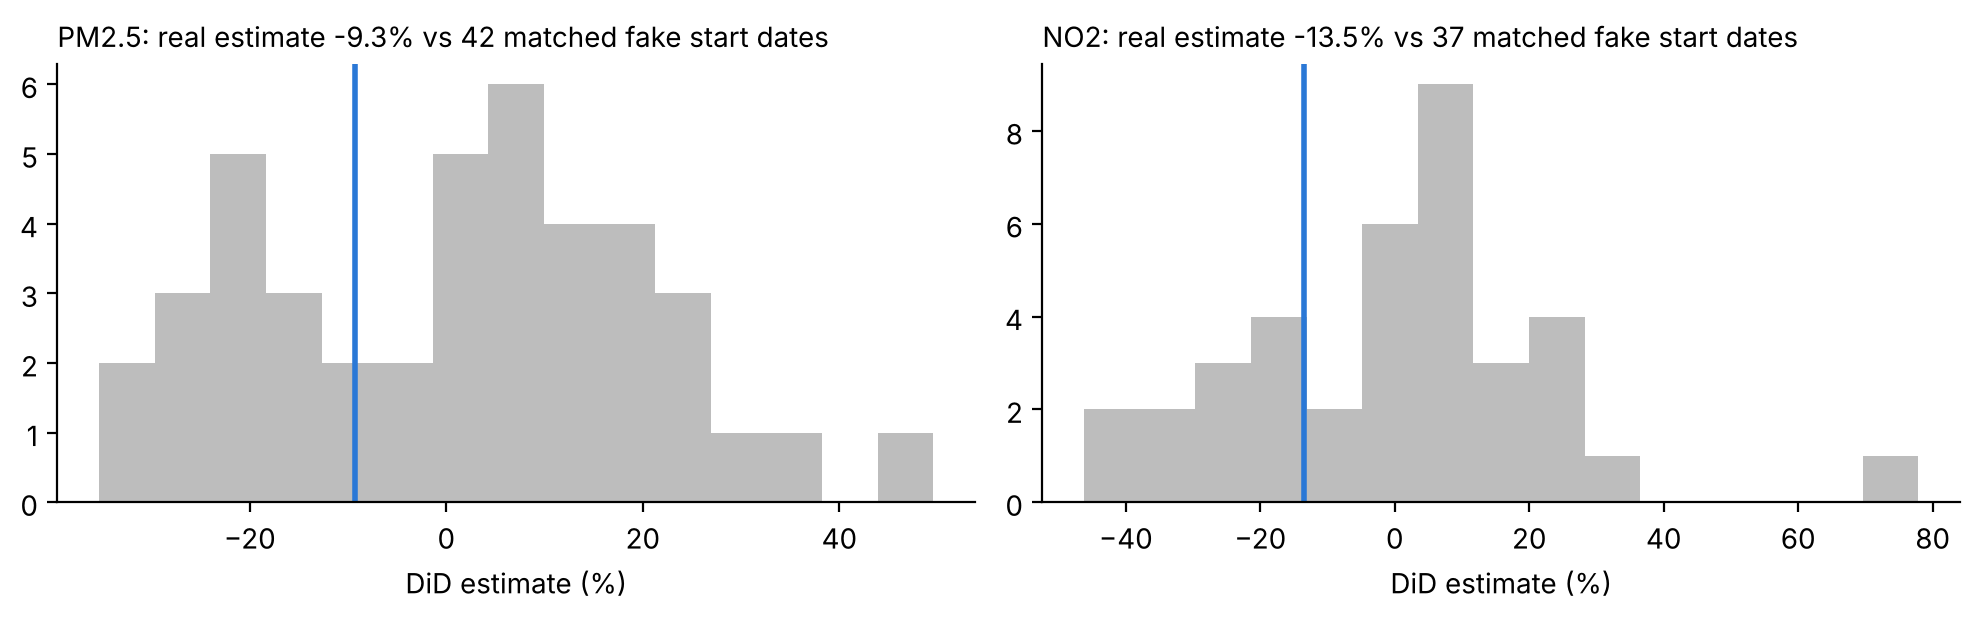

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, pol in zip(axes, ['PM2.5','NO2']):
    b, draws = RI_DRAWS[('Nov 2019', pol, '(2) DiD station FE (main)')]
    ax.hist(pct(draws), bins=15, color='#bdbdbd')
    ax.axvline(pct(b), color='#2a78d6', lw=2)
    ax.set_title(f'{pol}: real estimate {pct(b):.1f}% vs {len(draws)} matched fake start dates', loc='left', fontsize=10)
    ax.set_xlabel('DiD estimate (%)'); ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'appendix_ri_distribution.png'), dpi=160); plt.show()

### Does the placebo p-value depend on which years supply the fake start dates?
We compare the main (weekday-matched) fake dates with fake dates from 2017–2019 only (Gurugram's 2016 NO2 looks faulty)
with fake start dates in October–December only (same smog season), and with the earlier, looser version (any weekday, ±45 days).

In [14]:
sens = []
rule = ROUNDS['Nov 2019']; pre = pre_window(rule)
for pol in ['PM2.5','NO2']:
    f = lambda p, q, pol=pol: twfe(LEGACY10, GGN, pol, p, q)[0]
    b = f(pre, rule)
    for label, yrs, m in [('Matched weekday, ±75 days, all years (main)', None, True), ('Matched, 2017–2019 only', {2017, 2018, 2019}, True),
                          ('Matched, fake start in Oct–Dec only (smog season)', 'OND', True),
                          ('Any weekday, ±45 days (earlier version)', None, False)]:
        mo = {10, 11, 12} if yrs == 'OND' else None; yrs = None if yrs == 'OND' else yrs
        p, n, fk = ri(f, b, rule, yrs, m, mo); lo, hi = placebo_range(fk)
        sens.append(dict(Pollutant=pol, Fake_dates=label, Draws=n, Effect_pct=pct(b), placebo_p=p, placebo_p5=lo, placebo_p95=hi))
ri_sens = pd.DataFrame(sens); ri_sens.to_csv(os.path.join(OUT_DIR, 'ri_sensitivity.csv'), index=False)
ri_sens.round(2)

,Pollutant,Fake_dates,Draws,Effect_pct,placebo_p,placebo_p5,placebo_p95
0,PM2.5,"Matched weekday, ±75 days, all years (main)",42,-9.30,0.64,-26.24,30.40
1,PM2.5,"Matched, 2017–2019 only",29,-9.30,0.72,-26.05,27.62
2,PM2.5,"Matched, fake start in Oct–Dec only (smog season)",26,-9.30,0.65,-25.20,32.70
3,PM2.5,"Any weekday, ±45 days (earlier version)",206,-9.30,0.74,-28.26,47.75
4,NO2,"Matched weekday, ±75 days, all years (main)",37,-13.54,0.46,-35.86,28.39
5,NO2,"Matched, 2017–2019 only",29,-13.54,0.45,-30.37,32.23
6,NO2,"Matched, fake start in Oct–Dec only (smog season)",23,-13.54,0.43,-43.10,26.19
7,NO2,"Any weekday, ±45 days (earlier version)",167,-13.54,0.54,-45.09,38.85


## 9. Run log

In [15]:
with open(os.path.join(OUT_DIR, 'run_log.txt'), 'w') as f:
    f.write(f'Run at {pd.Timestamp.now()}\nDelhi stations with data: {len(ALL_DL)}\n\n')
    f.write('TABLE 1\n' + table1.round(2).to_string(index=False) + '\n\n')
    f.write('TABLE 2\n' + table2.round(4).to_string(index=False) + '\n\n')
    f.write('TABLE 3\n' + table3.to_string(index=False) + '\n\n')
    f.write('TABLE 3 APR 2016\n' + table3_apr.to_string(index=False) + '\n\n')
    f.write('STATION COVERAGE\n' + coverage.to_string(index=False) + '\n\n')
    f.write('WEEKDAY MIX\n' + weekday_mix.to_string(index=False) + '\n\n')
    f.write('PLACEBO SENSITIVITY\n' + ri_sens.round(3).to_string(index=False) + '\n\n')
    for pol in EVENT: f.write(f'FIGURE 1 {pol}\n' + EVENT[pol].round(2).to_string(index=False) + '\n\n')
print(open(os.path.join(OUT_DIR, 'run_log.txt')).read())

Run at 2026-11-19 16:02:12.427594
Delhi stations with data: 38

TABLE 1
   Round Pollutant                City Period  Days   Mean     SD  Median
Jan 2016     PM2.5 Delhi (10 monitors) Before    12 155.93  59.56  129.94
Jan 2016     PM2.5 Delhi (10 monitors) During    13 233.64  77.30  229.03
Jan 2016     PM2.5            Gurugram Before     0    NaN    NaN     NaN
Jan 2016     PM2.5            Gurugram During     0    NaN    NaN     NaN
Jan 2016       NO2 Delhi (10 monitors) Before    12  67.35  28.17   68.89
Jan 2016       NO2 Delhi (10 monitors) During    13  83.54  24.24   76.88
Jan 2016       NO2            Gurugram Before     8  14.83   2.05   14.20
Jan 2016       NO2            Gurugram During     6  12.15   3.54   11.09
Apr 2016     PM2.5 Delhi (10 monitors) Before    12  90.46  20.64   79.79
Apr 2016     PM2.5 Delhi (10 monitors) During    14 116.03  27.74  114.59
Apr 2016     PM2.5            Gurugram Before     6  76.56  13.48   78.02
Apr 2016     PM2.5            Gurugram D